In [ ]:
# =========================
# Celda A1 — Imports
# =========================
import numpy as np
import numpy.random as npr
import matplotlib.pyplot as plt
from dataclasses import dataclass

# Reglas para reproducibilidad
SEED_GLOBAL = 2025
npr.seed(SEED_GLOBAL)

# Estilo de gráficos (sin colores específicos)
plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True


In [ ]:
# =========================
# Celda A2 — Parámetros del modelo (p.21)
# =========================
@dataclass
class PPParams:
    n: int = 10     # instalaciones
    m: int = 5      # ubicaciones de demanda
    U: float = 200.0
    eps: float = 0.1          # nivel de riesgo ε
    mu_low: float = 10.0      # medias E[ζ_i] en [10,51]
    mu_high: float = 51.0
    sigma: float = 10.0       # desviación típica (igual para todas)
    cover_p: float = 0.5      # probabilidad T_ij=1 (cobertura)
    # Hiperparámetros del oráculo estocástico (Norkin'93)
    smooth_tau: float = 1.5   # temperatura del suavizado del indicador
    batch: int = 2048         # tamaño de minibatch para φ y gradientes
    var_M: int = 10000        # muestras para VaR_ε
    # Gradiente proyectado para x
    grad_steps: int = 150
    inner_epochs: int = 3
    step0: float = 4.0
    decay: float = 0.95
    # Alternancia de bloques (x,y)
    tol_y: float = 1e-6
    max_outer: int = 50

pp = PPParams()


In [ ]:
# =========================
# Celda B1 — Crear T, c, mu, sigma
# =========================
def make_instance(pp: PPParams, seed=123):
    rng = npr.default_rng(seed)
    T = rng.binomial(1, pp.cover_p, size=(pp.m, pp.n)).astype(float)
    # nos aseguramos que cada ubicación tenga al menos 1 instalación que la pueda cubrir
    for i in range(pp.m):
        if T[i].sum() == 0:
            T[i, rng.integers(pp.n)] = 1.0
    c = rng.integers(1, 11, size=pp.n).astype(float)       # costos 1..10
    mu = rng.uniform(pp.mu_low, pp.mu_high, size=pp.m)     # medias aleatorias en [10,51]
    sigma = np.full(pp.m, pp.sigma, dtype=float)
    return T, c, mu, sigma

T, c, mu, sigma = make_instance(pp, seed=123)

print("T shape:", T.shape)
print("c:", c)
print("mu:", mu.round(2))
print("sigma:", sigma)
print("Cobertura por ubicación:", T.sum(axis=1).astype(int))


T shape: (5, 10)
c: [9. 2. 3. 3. 4. 1. 5. 4. 6. 6.]
mu: [27.52 44.24 35.28 20.91 43.25]
sigma: [10. 10. 10. 10. 10.]
Cobertura por ubicación: [5 7 4 7 2]


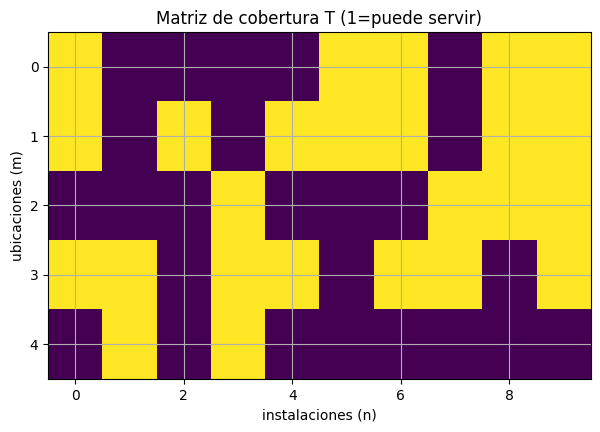

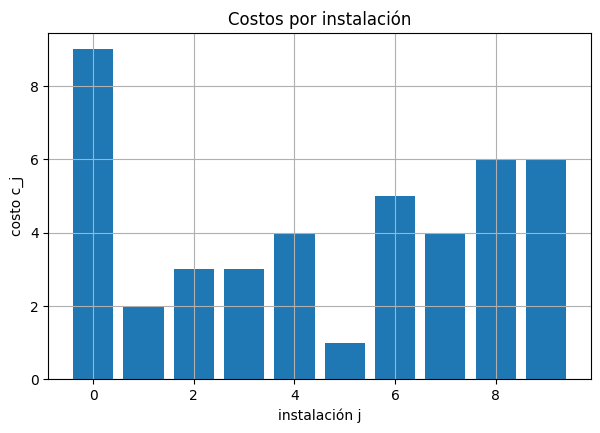

In [ ]:
# =========================
# Celda B2 — Visualización rápida
# =========================
fig, ax = plt.subplots()
ax.imshow(T, aspect="auto")
ax.set_xlabel("instalaciones (n)")
ax.set_ylabel("ubicaciones (m)")
ax.set_title("Matriz de cobertura T (1=puede servir)")
plt.show()

fig, ax = plt.subplots()
ax.bar(np.arange(len(c)), c)
ax.set_xlabel("instalación j")
ax.set_ylabel("costo c_j")
ax.set_title("Costos por instalación")
plt.show()


In [ ]:
# =========================
# Celda C1 — f(x,ζ), muestreo, proyección, VaR_ε y φ(x,y)
# =========================

def project_box_halfspace(x, u):
    """Proyecta x en {0 ≤ x ≤ U, c^T x ≤ u}."""
    x = np.clip(x, 0.0, pp.U)
    overflow = float(np.dot(c, x) - u)
    if overflow > 0:
        x = x - (overflow / (np.dot(c, c) + 1e-12)) * c
        x = np.clip(x, 0.0, pp.U)
    return x

def sample_zeta(M, rng):
    """ζ ~ N(μ, diag(σ^2)), independiente por componente."""
    return rng.normal(loc=mu, scale=sigma, size=(M, pp.m))

def f_margin(x, zeta):
    """f(x,ζ) = min_i ( (Tx)_i - ζ_i )."""
    Tx = T @ x               # (m,)
    return (Tx[None, :] - zeta).min(axis=1)  # (M,)

def var_epsilon(x, eps=None, M=None, seed=0):
    """VaR_ε(f(x,ζ)) como cuantil ε de f(x,ζ)."""
    if eps is None: eps = pp.eps
    if M   is None: M   = pp.var_M
    rng = npr.default_rng(seed)
    zeta = sample_zeta(M, rng)
    fval = f_margin(x, zeta)
    q = np.quantile(fval, eps)
    return float(max(0.0, q))  # el paper usa y ≥ 0

def phi_hat(x, y, B=None, seed=1):
    """
    φ(x,y) ≈ y * ( P[min_i ≥ s*y] - (1-ε) ), con s ~ U[0,1].
    Estimación Monte Carlo sin suavizado (para diagnóstico).
    """
    if B is None: B = pp.batch
    rng = npr.default_rng(seed)
    zeta = sample_zeta(B, rng)
    s = rng.uniform(0.0, 1.0, size=(B, 1))
    fval = f_margin(x, zeta).reshape(-1, 1)
    prob = (fval >= s * y).mean()
    return float(y * (prob - (1.0 - pp.eps)))


In [ ]:
# =========================
# Celda C2 — Oráculo estocástico suavizado para ∇_x φ(x,y)
# =========================

def phi_and_grad_x_smooth(x, y, rng, batch=None, tau=None):
    """
    Devuelve (φ̂, ĝ) donde φ̂ usa indicador sigmoide:
      σ(u) = 1/(1+e^{-u}),   u = (min_i(Tx-ζ_i) - s*y) / τ
    y el subgradiente de min via i* = argmin margen.
    """
    if batch is None: batch = pp.batch
    if tau   is None: tau   = pp.smooth_tau

    zeta = sample_zeta(batch, rng)
    s = rng.uniform(0.0, 1.0, size=(batch, 1))

    Tx = T @ x
    margin = Tx[None, :] - zeta
    mmin = margin.min(axis=1, keepdims=True)  # (B,1)

    u = (mmin - s*y) / tau
    sig = 1.0 / (1.0 + np.exp(-u))            # indicador suavizado
    phi = float(y * (sig.mean() - (1.0 - pp.eps)))

    # subgradiente de min: d(min)/dx_j = T_{i*,j}
    argmin = np.argmin(margin, axis=1)
    sigp = sig * (1.0 - sig) / tau           # derivada de σ
    grad = np.zeros_like(x)
    for j in range(pp.n):
        contrib = T[:, j][argmin]            # (B,)
        grad[j] = float((y * sigp[:, 0] * contrib).mean())
    return phi, grad


(Chequeo) costo=300.00, y(VaR)=87.6997, φ≈8.3161


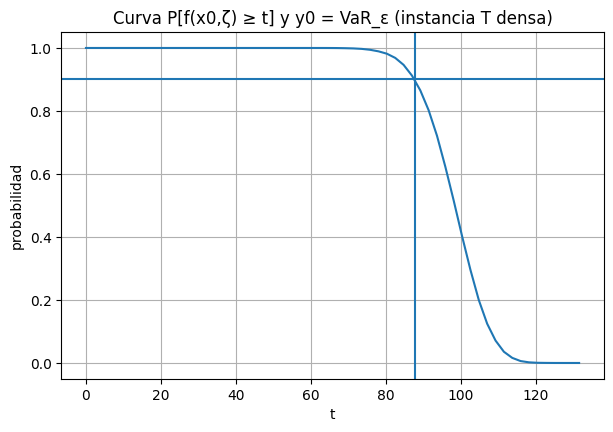

In [ ]:
# =========================
# D1-fix — Hacer T denso y repetir D1
# =========================
pp.cover_p = 1.0  # todas las instalaciones cubren todas las ubicaciones
T, c, mu, sigma = make_instance(pp, seed=456)  # rehacemos instancia

# recomputamos x0 voraz para u0=300
x0 = np.zeros(pp.n)
for j in np.argsort(c):
    add = min(pp.U, (u0 - np.dot(c, x0)) / max(c[j],1e-9))
    if add > 0: x0[j] += add
x0 = project_box_halfspace(x0, u0)

# re-evaluamos y0 y φ
y0 = var_epsilon(x0, seed=10)
phi0 = phi_hat(x0, y0, B=5*pp.batch, seed=11)
print(f"(Chequeo) costo={np.dot(c,x0):.2f}, y(VaR)={y0:.4f}, φ≈{phi0:.4f}")

# Curva P[f≥t]
rng = npr.default_rng(12)
z = sample_zeta(40000, rng)
fvals = f_margin(x0, z)
ts = np.linspace(0, max(1.0, y0*1.5), 60)
probs = [(fvals >= t).mean() for t in ts]

plt.figure()
plt.plot(ts, probs)
plt.axhline(1-pp.eps)
plt.axvline(y0)
plt.title("Curva P[f(x0,ζ) ≥ t] y y0 = VaR_ε (instancia T densa)")
plt.xlabel("t"); plt.ylabel("probabilidad")
plt.show()


In [ ]:
# =========================
# Celda E1 — Algoritmo 1: evaluar ρ(u) y guardar trazas
# =========================

def solve_rho(u, seed=2026,
              max_outer=None, inner_epochs=None, grad_steps=None,
              step0=None, tau=None, batch=None, verbose=True):
    if max_outer    is None: max_outer    = pp.max_outer
    if inner_epochs is None: inner_epochs = pp.inner_epochs
    if grad_steps   is None: grad_steps   = pp.grad_steps
    if step0        is None: step0        = pp.step0
    if tau          is None: tau          = pp.smooth_tau
    if batch        is None: batch        = pp.batch

    rng = npr.default_rng(seed)

    # x inicial "voraz" respetando c^T x ≤ u
    x = np.zeros(pp.n)
    for j in np.argsort(c):
        add = min(pp.U, (u - np.dot(c, x)) / max(c[j],1e-9))
        if add > 0: x[j] += add
    x = project_box_halfspace(x, u)

    # y inicial = VaR_ε
    y = var_epsilon(x, M=pp.var_M, seed=rng.integers(1,10**9))

    hist = []
    best_phi, best_xy = -1e18, (x.copy(), y)

    for it in range(max_outer):
        # (1) y | x  (cierre por VaR)
        y_new = var_epsilon(x, M=pp.var_M, seed=rng.integers(1,10**9))

        # (2) x | y  (ascenso proyectado con oráculo estocástico)
        step = step0
        for ep in range(inner_epochs):
            for k in range(grad_steps):
                phi_est, gx = phi_and_grad_x_smooth(x, y_new, rng, batch=batch, tau=tau)
                x = x + (step / (1.0 + k/50.0)) * gx
                x = project_box_halfspace(x, u)
            step *= pp.decay

        phi_eval, _ = phi_and_grad_x_smooth(x, y_new, rng, batch=batch, tau=tau)
        hist.append({"it": it, "y": y_new, "phi": phi_eval, "cost": float(np.dot(c,x))})

        if verbose:
            print(f"it={it:02d}  y={y_new:.6f}  φ={phi_eval:.6f}  costo={np.dot(c,x):.2f}")

        if phi_eval > best_phi:
            best_phi, best_xy = phi_eval, (x.copy(), y_new)

        if it>0 and abs(hist[-1]["y"] - hist[-2]["y"]) <= pp.tol_y:
            break
        y = y_new

    return best_phi, best_xy[0], best_xy[1], hist


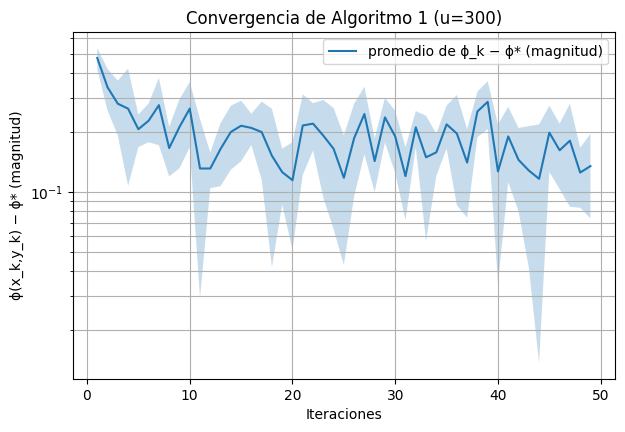

In [ ]:
# =========================
# Celda F1 — Convergencia de Algoritmo 1 (u=300)
# =========================
u_fig = 300.0
n_runs = 5
maxit_plot = 49

series = []
for r in range(n_runs):
    rho_u, x_u, y_u, hist = solve_rho(u_fig, seed=3000+r, verbose=False)
    phi_star = max(h["phi"] for h in hist)         # ϕ* ≈ mejor valor alcanzado en esa corrida
    s = []
    for k in range(maxit_plot):
        s.append((hist[k]["phi"] if k < len(hist) else s[-1]) - phi_star)
    series.append(s)

series = np.array(series)
avg = series.mean(axis=0)
std = series.std(axis=0)

plt.figure()
plt.semilogy(np.arange(1, maxit_plot+1), -avg, label="promedio de ϕ_k − ϕ* (magnitud)")
plt.fill_between(np.arange(1, maxit_plot+1), -(avg+std), -(avg-std), alpha=0.25)
plt.xlabel("Iteraciones"); plt.ylabel("ϕ(x_k,y_k) − ϕ* (magnitud)")
plt.title("Convergencia de Algoritmo 1 (u=300)")
plt.legend(); plt.grid(True, which="both")
plt.show()


it=00  y=87.736913  φ=8.462223  costo=308.32
it=01  y=91.452660  φ=8.818410  costo=312.07
it=02  y=93.588307  φ=9.006648  costo=314.61
it=03  y=94.406456  φ=9.053519  costo=315.36
it=04  y=95.430759  φ=8.865032  costo=316.64
it=05  y=95.597688  φ=9.063399  costo=316.64
it=06  y=95.918839  φ=8.829320  costo=317.05
it=07  y=95.786762  φ=9.005240  costo=316.79
it=08  y=95.788341  φ=9.134373  costo=316.71
it=09  y=95.816784  φ=9.124240  costo=316.88
it=10  y=95.779085  φ=9.246122  costo=316.85
it=11  y=96.222088  φ=9.013174  costo=317.42
it=12  y=96.482232  φ=8.940716  costo=317.79
it=13  y=96.473687  φ=9.136389  costo=317.58
it=14  y=96.316425  φ=9.301966  costo=317.45
it=15  y=96.450155  φ=9.152019  costo=317.74
it=16  y=96.610931  φ=9.080769  costo=317.87
it=17  y=96.607454  φ=9.075358  costo=317.44
it=18  y=96.213167  φ=8.897663  costo=317.19
it=19  y=96.117422  φ=9.121089  costo=317.40
it=20  y=96.365616  φ=9.175379  costo=317.53
it=21  y=96.256759  φ=9.245243  costo=317.33
it=22  y=9

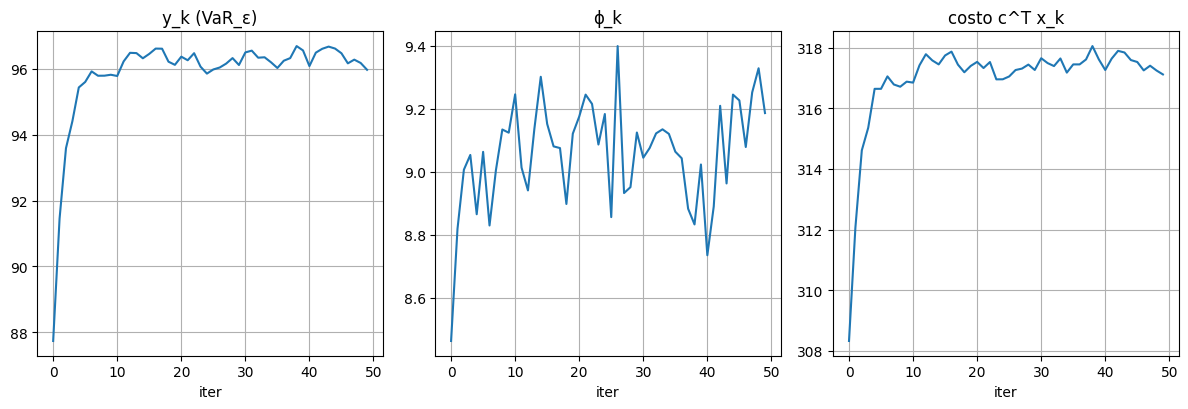

In [ ]:
# =========================
# Celda F2 — y_k, φ_k, y costo por iteración (u=300)
# =========================
rho_u, x_u, y_u, hist = solve_rho(u_fig, seed=4444, verbose=True)
its  = [h["it"]  for h in hist]
ys   = [h["y"]   for h in hist]
phis = [h["phi"] for h in hist]
cost = [h["cost"] for h in hist]

fig, axs = plt.subplots(1,3, figsize=(12,4.2))
axs[0].plot(its, ys);   axs[0].set_title("y_k (VaR_ε)")
axs[1].plot(its, phis); axs[1].set_title("ϕ_k")
axs[2].plot(its, cost); axs[2].set_title("costo c^T x_k")
for a in axs: a.set_xlabel("iter"); a.grid(True)
plt.tight_layout(); plt.show()



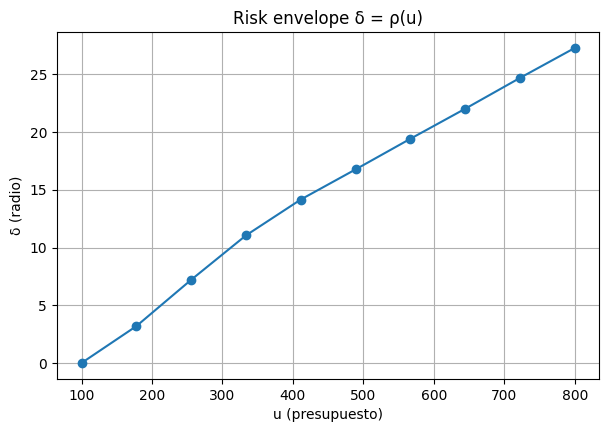

In [ ]:
# =========================
# Celda G1 — Risk envelope: δ = ρ(u)
# =========================
budgets = np.linspace(100, 800, 10)
rhos, ys_opt, costs, xs_opt = [], [], [], []
rng = npr.default_rng(9001)

for u in budgets:
    rho_u, x_opt, y_opt, _ = solve_rho(float(u), seed=rng.integers(1,10**9), verbose=False)
    rhos.append(rho_u); ys_opt.append(y_opt)
    costs.append(float(np.dot(c, x_opt))); xs_opt.append(x_opt)

plt.figure()
plt.plot(budgets, rhos, marker="o")
plt.xlabel("u (presupuesto)"); plt.ylabel("δ (radio)")
plt.title("Risk envelope δ = ρ(u)")
plt.grid(True)
plt.show()


u=300.0  δ≈9.3492  y*=96.4030  costo=317.70
P[f(x*,ζ) ≥ y*] ≈ 0.8973  (target 0.9000)


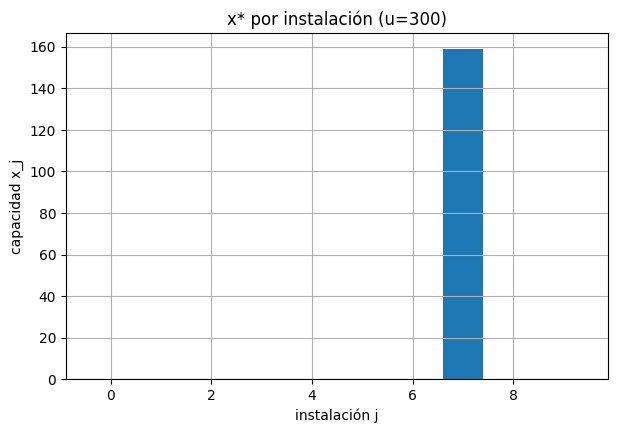

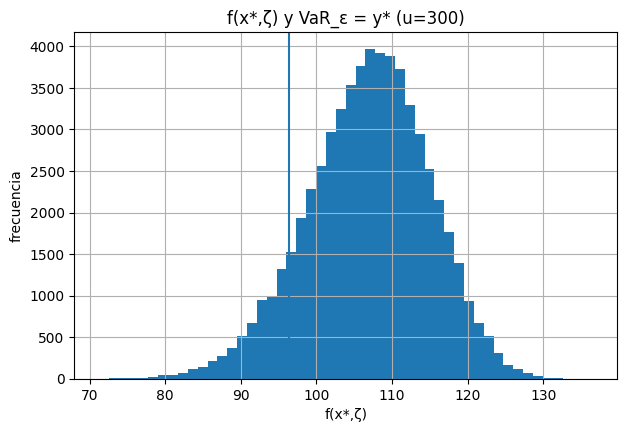

In [ ]:
# =========================
# Celda G2 — Verificación (P-CC) en x* para u=300
# =========================
u_check = 300.0
rho_u, x_star, y_star, _ = solve_rho(u_check, seed=7777, verbose=False)

print(f"u={u_check:.1f}  δ≈{rho_u:.4f}  y*={y_star:.4f}  costo={np.dot(c,x_star):.2f}")

rng = npr.default_rng(888)
z = sample_zeta(60000, rng)
fvals = f_margin(x_star, z)
prob = (fvals >= y_star).mean()
print(f"P[f(x*,ζ) ≥ y*] ≈ {prob:.4f}  (target {1-pp.eps:.4f})")

# x* por instalación
plt.figure()
plt.bar(np.arange(pp.n), x_star)
plt.title("x* por instalación (u=300)")
plt.xlabel("instalación j"); plt.ylabel("capacidad x_j")
plt.grid(True); plt.show()

# Distribución de f(x*,ζ) y marca en y*
plt.figure()
plt.hist(fvals, bins=50)
plt.axvline(y_star)
plt.title("f(x*,ζ) y VaR_ε = y* (u=300)")
plt.xlabel("f(x*,ζ)"); plt.ylabel("frecuencia")
plt.grid(True); plt.show()



In [ ]:
# Recomendados si notas serrucho o varianza alta:
pp.batch    = 4096      # más muestras por φ y grad
pp.var_M    = 20000     # más muestras para VaR
pp.step0    = 3.5       # paso inicial un poco menor
pp.grad_steps = 200
pp.inner_epochs = 3
pp.smooth_tau = 2.0     # suaviza más el indicador


In [ ]:
import pandas as pd
df_env = pd.DataFrame({"u": budgets, "rho": rhos, "y_opt": ys_opt, "cost": costs})
df_env.to_csv("risk_envelope.csv", index=False)
